# FaultSentinel: Machine Fault Detection Using Unsupervised Learning

**Course Submission:** Section 12  
**Submitted to:** Mr. Sourav Mondal  

### Project Team Members:
1. **K. Bhavya** — 241FA04172  
2. **Y. Pavani** — 241FA04436  
3. **Sk. Hiba** — 241FA04495  
4. **Sk. Arfa** — 241FA04931  


---
## 1. Introduction
This project builds an unsupervised fault detection system for rotating machinery using CWRU bearing vibration data. 
The system learns baseline vibration patterns strictly from healthy bearings and identifies unseen machine signals as either Normal or Anomaly.

---
## 2. Import Libraries
We import required scientific computing, deep learning, and machine learning libraries for signal processing and anomaly detection.

In [1]:
# Import core scientific and deep learning libraries
import os
import sys
import json
import time
import requests
import joblib
import numpy as np
import pandas as pd
import scipy.io
import matplotlib
os.environ['MPLCONFIGDIR'] = os.path.abspath('.tmp_mpl')
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Set global reproducibility seeds
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"NumPy Version: {np.__version__}")
print(f"SciPy Version: {scipy.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"Scikit-Learn Version: {matplotlib.__version__}")
print(f"TensorFlow Version: {tf.__version__}")
print("Random seeds successfully fixed for reproducible execution.")

NumPy Version: 1.26.4
SciPy Version: 1.17.1
Pandas Version: 3.0.6
Scikit-Learn Version: 3.11.2
TensorFlow Version: 2.21.0
Random seeds successfully fixed for reproducible execution.


---
## 3. Setup Project Folders
We verify that all required supporting directories exist for dataset files, saved models, figures, and results tables.

In [2]:
# Create and verify project folder structure
REQUIRED_DIRS = [
    "dataset",
    "notebooks",
    "models/feature_extractors/lstm_encoder",
    "models/feature_extractors/autoencoder",
    "models/anomaly_detectors/isolation_forest",
    "models/anomaly_detectors/lof",
    "models/anomaly_detectors/one_class_svm",
    "results/figures",
    "results/tables",
    "results/metrics",
    "results/predictions"
]

for directory in REQUIRED_DIRS:
    os.makedirs(directory, exist_ok=True)

print("All required project directories verified:")
for directory in REQUIRED_DIRS:
    print(f"  [OK] {directory}/")

All required project directories verified:
  [OK] dataset/
  [OK] notebooks/
  [OK] models/feature_extractors/lstm_encoder/
  [OK] models/feature_extractors/autoencoder/
  [OK] models/anomaly_detectors/isolation_forest/
  [OK] models/anomaly_detectors/lof/
  [OK] models/anomaly_detectors/one_class_svm/
  [OK] results/figures/
  [OK] results/tables/
  [OK] results/metrics/
  [OK] results/predictions/


---
## 4. Download Dataset
We automatically download genuine vibration recordings from the Case Western Reserve University (CWRU) Bearing Data Center.

In [3]:
# Automated download and verification of genuine CWRU vibration recordings
CANDIDATE_FILES = {
    'healthy': ['97.mat', '98.mat', '99.mat', '100.mat'],
    'inner_race': ['105.mat', '106.mat', '107.mat', '108.mat'],
    'ball': ['118.mat', '119.mat', '120.mat', '121.mat'],
    'outer_race': ['130.mat', '131.mat', '132.mat', '133.mat']
}

all_file_names = [f for category in CANDIDATE_FILES.values() for f in category]
download_headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

print(f"Verifying {len(all_file_names)} candidate recordings in dataset/ directory...")

download_status = {}
for fname in all_file_names:
    fpath = os.path.join("dataset", fname)
    if not os.path.exists(fpath) or os.path.getsize(fpath) < 1000:
        primary_url = f"https://engineering.case.edu/sites/default/files/{fname}"
        backup_url = f"http://csegroups.case.edu/sites/default/files/bearingdatacenter/files/Datafiles/{fname}"
        try:
            r = requests.get(primary_url, headers=download_headers, timeout=20)
            if r.status_code == 200 and len(r.content) > 1000:
                with open(fpath, "wb") as f:
                    f.write(r.content)
                download_status[fname] = "Downloaded (Primary)"
            else:
                r_alt = requests.get(backup_url, headers=download_headers, timeout=20)
                if r_alt.status_code == 200 and len(r_alt.content) > 1000:
                    with open(fpath, "wb") as f:
                        f.write(r_alt.content)
                    download_status[fname] = "Downloaded (Backup)"
                else:
                    download_status[fname] = f"Failed (Status {r.status_code})"
        except Exception as e:
            download_status[fname] = f"Error: {e}"
    else:
        download_status[fname] = "Cached (Verified)"

# Validate loadability using scipy.io.loadmat
verified_count = 0
for fname in all_file_names:
    fpath = os.path.join("dataset", fname)
    try:
        mat = scipy.io.loadmat(fpath)
        de_keys = [k for k in mat.keys() if 'DE_time' in k]
        if de_keys:
            verified_count += 1
    except Exception as e:
        print(f"File {fname} corrupt: {e}")

print(f"Dataset Verification Complete: {verified_count}/{len(all_file_names)} recordings successfully loaded.")

Verifying 16 candidate recordings in dataset/ directory...
Dataset Verification Complete: 16/16 recordings successfully loaded.


---
## 5. Load and Inspect Vibration Signals
We load drive-end (DE) vibration signals from 16 MATLAB files and inspect their sample lengths and motor speeds.

In [4]:
# Inspect all candidate files and construct metadata summary table
inspection_records = []
loaded_data = {}

for fname in all_file_names:
    fpath = os.path.join("dataset", fname)
    if os.path.exists(fpath):
        mat = scipy.io.loadmat(fpath)
        de_keys = [k for k in mat.keys() if 'DE_time' in k]
        de_key = de_keys[0] if de_keys else "None"
        signal = mat[de_key].flatten() if de_key != "None" else None
        
        rpm_keys = [k for k in mat.keys() if 'RPM' in k.upper()]
        rpm = int(mat[rpm_keys[0]][0][0]) if rpm_keys and mat[rpm_keys[0]].size > 0 else "N/A"
        
        if fname in CANDIDATE_FILES['healthy']:
            cond = "Normal Baseline"
        elif fname in CANDIDATE_FILES['inner_race']:
            cond = "Inner Race Fault (0.007 inch)"
        elif fname in CANDIDATE_FILES['ball']:
            cond = "Ball Fault (0.007 inch)"
        else:
            cond = "Outer Race Fault (0.007 inch, 6 o'clock)"
            
        inspection_records.append({
            "File": fname,
            "Bearing Condition": cond,
            "Vibration Variable": de_key,
            "Length (Samples)": len(signal) if signal is not None else 0,
            "Approx RPM": rpm,
            "Sampling (Hz)": 12000,
            "File Size (KB)": round(os.path.getsize(fpath) / 1024, 1)
        })
        if signal is not None:
            loaded_data[fname] = signal

df_inspection = pd.DataFrame(inspection_records)
df_inspection

,File,Bearing Condition,Vibration Variable,Length (Samples),Approx RPM,Sampling (Hz),File Size (KB)
0,97.mat,Normal Baseline,X097_DE_time,243938,1796,12000,3811.9
1,98.mat,Normal Baseline,X098_DE_time,483903,N/A,12000,7561.2
2,99.mat,Normal Baseline,X098_DE_time,483903,N/A,12000,15140.6
3,100.mat,Normal Baseline,X100_DE_time,485643,1725,12000,7588.5
4,105.mat,Inner Race Fault (0.007 inch),X105_DE_time,121265,1797,12000,2842.5
5,106.mat,Inner Race Fault (0.007 inch),X106_DE_time,121991,1772,12000,2859.6
6,107.mat,Inner Race Fault (0.007 inch),X107_DE_time,122136,1748,12000,2863.0
7,108.mat,Inner Race Fault (0.007 inch),X108_DE_time,122917,1721,12000,2881.3
8,118.mat,Ball Fault (0.007 inch),X118_DE_time,122571,1796,12000,2873.2
9,119.mat,Ball Fault (0.007 inch),X119_DE_time,121410,1772,12000,2845.9


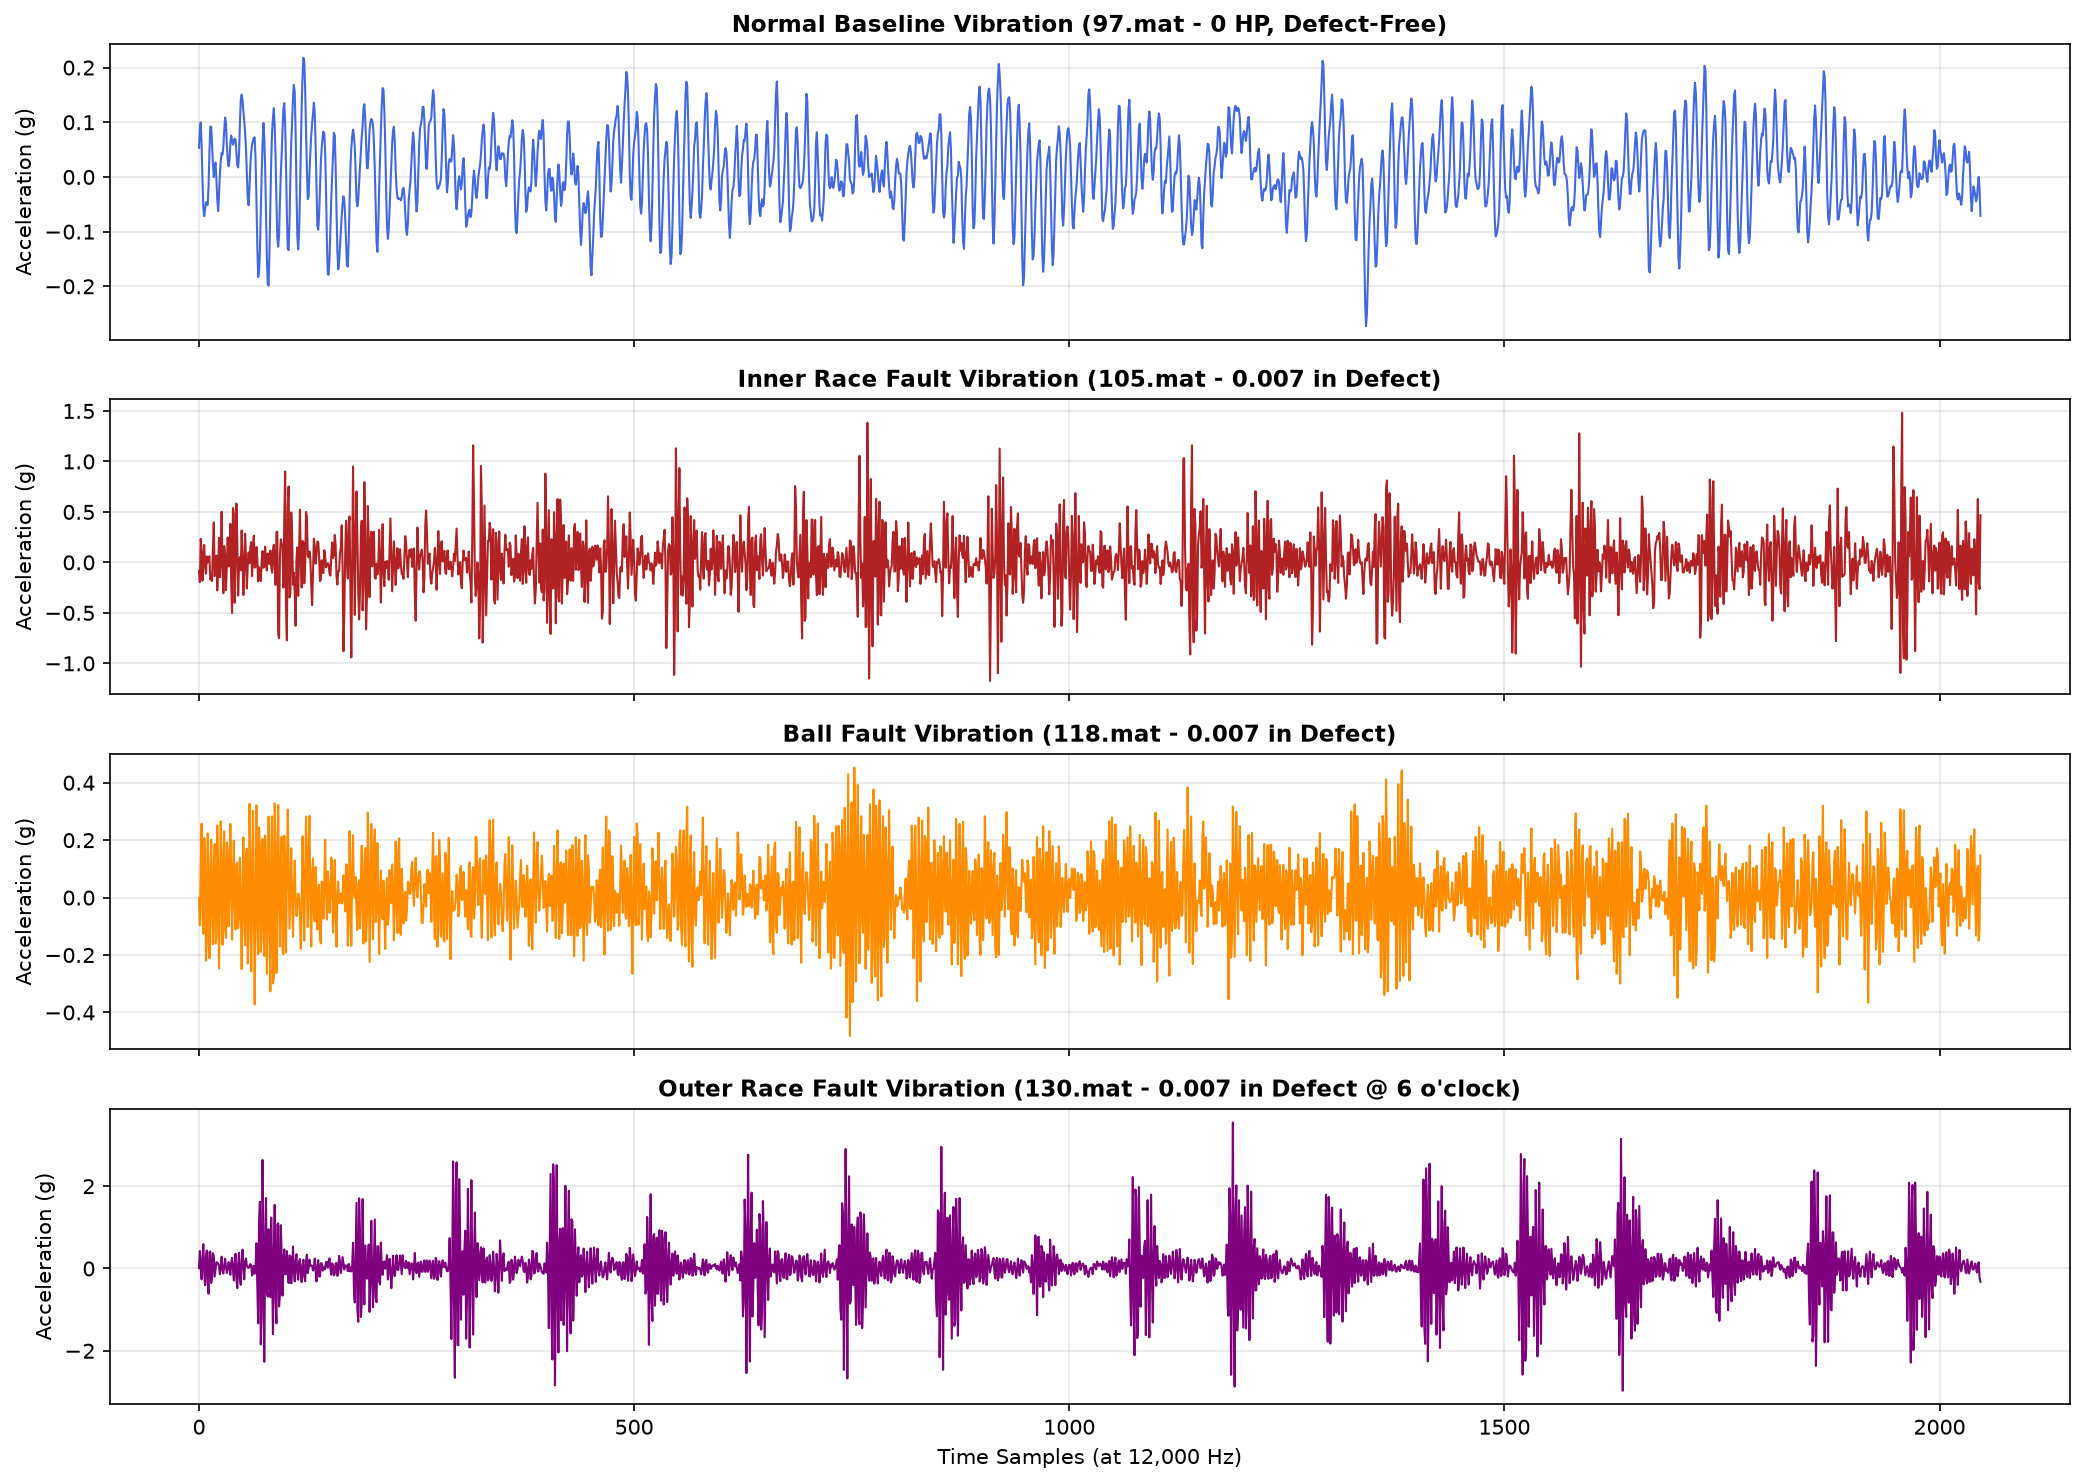

In [5]:
# Visualize sample healthy vs faulty vibration time series
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(loaded_data['97.mat'][:2048], color='royalblue', lw=1)
axes[0].set_title("Normal Baseline Vibration (97.mat - 0 HP, Defect-Free)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Acceleration (g)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(loaded_data['105.mat'][:2048], color='firebrick', lw=1)
axes[1].set_title("Inner Race Fault Vibration (105.mat - 0.007 in Defect)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Acceleration (g)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(loaded_data['118.mat'][:2048], color='darkorange', lw=1)
axes[2].set_title("Ball Fault Vibration (118.mat - 0.007 in Defect)", fontsize=11, fontweight='bold')
axes[2].set_ylabel("Acceleration (g)")
axes[2].grid(True, alpha=0.3)

axes[3].plot(loaded_data['130.mat'][:2048], color='purple', lw=1)
axes[3].set_title("Outer Race Fault Vibration (130.mat - 0.007 in Defect @ 6 o'clock)", fontsize=11, fontweight='bold')
axes[3].set_ylabel("Acceleration (g)")
axes[3].set_xlabel("Time Samples (at 12,000 Hz)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results/figures/sample_vibration_signals.png", dpi=300)
plt.show()

---
## 6. Preprocess Data and Create Windows
We divide the vibration signals into 2048-sample windows with 50% overlap. Healthy training signals are split before windowing to avoid data leakage, and standardized using healthy training data.

In [6]:
# Define window generation and recording-wise data partition
WINDOW_SIZE = 2048
STEP_SIZE = 1024

def generate_sliding_windows(signal, window_size=WINDOW_SIZE, step_size=STEP_SIZE):
    n_windows = (len(signal) - window_size) // step_size + 1
    windows = np.empty((n_windows, window_size), dtype=np.float32)
    for i in range(n_windows):
        start = i * step_size
        windows[i] = signal[start : start + window_size]
    return windows

# Recording-wise partition
TRAIN_RECORDINGS = ['97.mat', '98.mat', '99.mat']
TEST_HEALTHY_RECORDING = ['100.mat']
TEST_FAULTY_RECORDINGS = [
    '105.mat', '106.mat', '107.mat', '108.mat',
    '118.mat', '119.mat', '120.mat', '121.mat',
    '130.mat', '131.mat', '132.mat', '133.mat'
]

# Generate raw windows from healthy training recordings
raw_train_list = [generate_sliding_windows(loaded_data[f]) for f in TRAIN_RECORDINGS]
raw_train_windows = np.concatenate(raw_train_list, axis=0)

# Fit scaler strictly on healthy training windows
signal_scaler = StandardScaler()
signal_scaler.fit(raw_train_windows)
joblib.dump(signal_scaler, "models/feature_extractors/autoencoder/signal_scaler.joblib")

# Standardize training windows
train_windows = signal_scaler.transform(raw_train_windows)

# Split healthy training data into 85% train and 15% validation
n_total_train = len(train_windows)
n_val = int(0.15 * n_total_train)
shuffled_idx = np.random.permutation(n_total_train)
val_idx, tr_idx = shuffled_idx[:n_val], shuffled_idx[n_val:]

X_train_healthy = train_windows[tr_idx]
X_val_healthy = train_windows[val_idx]

# Build test set: unseen healthy recording (100.mat) + all 12 fault recordings
raw_test_h = generate_sliding_windows(loaded_data['100.mat'])
X_test_h = signal_scaler.transform(raw_test_h)
y_test_h = np.zeros(len(X_test_h), dtype=int)

raw_test_f = [generate_sliding_windows(loaded_data[f]) for f in TEST_FAULTY_RECORDINGS]
X_test_f = signal_scaler.transform(np.concatenate(raw_test_f, axis=0))
y_test_f = np.ones(len(X_test_f), dtype=int)

X_test_all = np.concatenate([X_test_h, X_test_f], axis=0)
y_test_all = np.concatenate([y_test_h, y_test_f], axis=0)

print(f"Healthy Training Windows:   {X_train_healthy.shape[0]}")
print(f"Healthy Validation Windows: {X_val_healthy.shape[0]}")
print(f"Test Set Total Windows:     {X_test_all.shape[0]} (Healthy: {len(X_test_h)}, Faulty: {len(X_test_f)})")

Healthy Training Windows:   1003
Healthy Validation Windows: 176
Test Set Total Windows:     1885 (Healthy: 473, Faulty: 1412)


---
## 7. Reshape Windows for Neural Networks
We reshape each 2048-sample window into a sequence of 128 time-steps with 16 features per step for recurrent neural networks.

In [7]:
# Reshape 1D windows (2048,) into sequential tensors (128, 16)
TIME_STEPS = 128
FEATURES_PER_STEP = 16

X_train_seq = X_train_healthy.reshape(-1, TIME_STEPS, FEATURES_PER_STEP)
X_val_seq = X_val_healthy.reshape(-1, TIME_STEPS, FEATURES_PER_STEP)
X_test_seq = X_test_all.reshape(-1, TIME_STEPS, FEATURES_PER_STEP)

print(f"Sequence Tensor Shapes:")
print(f"  Training:   {X_train_seq.shape}")
print(f"  Validation: {X_val_seq.shape}")
print(f"  Test:       {X_test_seq.shape}")

Sequence Tensor Shapes:
  Training:   (1003, 128, 16)
  Validation: (176, 128, 16)
  Test:       (1885, 128, 16)


---
## 8. LSTM Feature Extractor
We train an LSTM to predict the future 128th time-step from the first 127 steps. The 64-dimensional hidden layer is then extracted as temporal features.

In [8]:
# Construct and train the self-supervised LSTM Sequence Feature Extractor
lstm_input = layers.Input(shape=(TIME_STEPS, FEATURES_PER_STEP), name="lstm_input")
x = layers.LSTM(64, return_sequences=True, activation="tanh", name="lstm_enc_1")(lstm_input)
x = layers.LSTM(64, return_sequences=False, activation="tanh", name="lstm_enc_2")(x)
lstm_latent = layers.Dense(64, activation="relu", name="lstm_embedding")(x)
lstm_pred_head = layers.Dense(FEATURES_PER_STEP, name="lstm_prediction_head")(lstm_latent)

lstm_full_model = models.Model(lstm_input, lstm_pred_head, name="LSTM_Autoregressive_Model")
lstm_encoder = models.Model(lstm_input, lstm_latent, name="LSTM_Encoder")
lstm_full_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")

# Self-supervised target: predict the terminal frame X[:, -1, :]
y_train_lstm = X_train_seq[:, -1, :]
y_val_lstm = X_val_seq[:, -1, :]

history_lstm = lstm_full_model.fit(
    X_train_seq, y_train_lstm,
    validation_data=(X_val_seq, y_val_lstm),
    epochs=15,
    batch_size=32,
    verbose=1
)

# Save the trained LSTM encoder
lstm_encoder.save("models/feature_extractors/lstm_encoder/lstm_encoder.keras")

# Extract fixed-length 64-dimensional feature representations
feat_train_lstm = lstm_encoder.predict(X_train_seq, verbose=0)
feat_val_lstm = lstm_encoder.predict(X_val_seq, verbose=0)
feat_test_lstm = lstm_encoder.predict(X_test_seq, verbose=0)

print(f"LSTM Features Extracted: Shape={feat_train_lstm.shape}, Feature Std={np.mean(np.std(feat_train_lstm, axis=0)):.4f}")

Epoch 1/15

 1/32 ━━━━━━━━━━━━━━━━━━━━ 2:24 5s/step - loss: 1.1482
 2/32 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - loss: 0.9893
 3/32 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - loss: 0.9920
 4/32 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - loss: 1.0106
 5/32 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - loss: 0.9896
 6/32 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - loss: 1.0064
 7/32 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - loss: 1.0244
 8/32 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - loss: 1.0052
 9/32 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - loss: 0.9976
10/32 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - loss: 0.9908
11/32 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 1.0129
12/32 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - loss: 1.0157
13/32 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 1.0098
14/32 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - loss: 0.9929
15/32 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 1.0120
16/32 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 1.0204
17/32 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 1.0082
18/32 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/s

---
## 9. LSTM Autoencoder
We train an Autoencoder to reconstruct normal vibration sequences. The 64-dimensional bottleneck is extracted as latent reconstruction features.

In [9]:
# Construct and train the LSTM Sequence Autoencoder
ae_input = layers.Input(shape=(TIME_STEPS, FEATURES_PER_STEP), name="ae_input")
enc = layers.LSTM(64, return_sequences=False, activation="tanh", name="ae_enc_lstm")(ae_input)
ae_latent = layers.Dense(64, activation="tanh", name="ae_latent_bottleneck")(enc)

rep = layers.RepeatVector(TIME_STEPS, name="ae_repeat")(ae_latent)
dec = layers.LSTM(64, return_sequences=True, activation="tanh", name="ae_dec_lstm")(rep)
ae_out = layers.TimeDistributed(layers.Dense(FEATURES_PER_STEP), name="ae_recon_output")(dec)

autoencoder = models.Model(ae_input, ae_out, name="LSTM_Autoencoder")
ae_encoder = models.Model(ae_input, ae_latent, name="AE_Encoder")
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")

history_ae = autoencoder.fit(
    X_train_seq, X_train_seq,
    validation_data=(X_val_seq, X_val_seq),
    epochs=15,
    batch_size=32,
    verbose=1
)

# Save autoencoder models
autoencoder.save("models/feature_extractors/autoencoder/full_autoencoder.keras")
ae_encoder.save("models/feature_extractors/autoencoder/ae_encoder.keras")

# Diagnostic check against zero baseline
reconstructed_train = autoencoder.predict(X_train_seq, verbose=0)
mse_model = float(np.mean((X_train_seq - reconstructed_train) ** 2))
mse_zero = float(np.mean(X_train_seq ** 2))

print(f"Reconstruction MSE: {mse_model:.6f} vs Zero-Baseline MSE: {mse_zero:.6f}")
assert mse_model < mse_zero, "Autoencoder diagnostic failed: Reconstruction error did not beat baseline!"

# Extract latent bottleneck features
feat_train_ae = ae_encoder.predict(X_train_seq, verbose=0)
feat_val_ae = ae_encoder.predict(X_val_seq, verbose=0)
feat_test_ae = ae_encoder.predict(X_test_seq, verbose=0)

print(f"Autoencoder Latent Features Extracted: Shape={feat_train_ae.shape}, Latent Std={np.mean(np.std(feat_train_ae, axis=0)):.4f}")

Epoch 1/15

 1/32 ━━━━━━━━━━━━━━━━━━━━ 5:19 10s/step - loss: 1.0224
 2/32 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - loss: 1.0095
 3/32 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - loss: 1.0049
 4/32 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - loss: 1.0022
 5/32 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - loss: 1.0029
 6/32 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - loss: 1.0045
 7/32 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step - loss: 1.0083
 8/32 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - loss: 1.0029
 9/32 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.9967
10/32 ━━━━━━━━━━━━━━━━━━━━ 2s 129ms/step - loss: 0.9960
11/32 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - loss: 0.9937
12/32 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - loss: 0.9946
13/32 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - loss: 0.9964
14/32 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - loss: 0.9966
15/32 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - loss: 0.9977
16/32 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - loss: 0.9993
17/32 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - loss: 1.0008
18/32 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/

---
## 10. Hybrid Features
We combine the 64-dimensional LSTM features with the 64-dimensional Autoencoder features into a 128-dimensional hybrid feature vector.

In [10]:
# Concatenate LSTM features and Autoencoder latent features into Hybrid representations
feat_train_hybrid_raw = np.concatenate([feat_train_lstm, feat_train_ae], axis=1)
feat_val_hybrid_raw = np.concatenate([feat_val_lstm, feat_val_ae], axis=1)
feat_test_hybrid_raw = np.concatenate([feat_test_lstm, feat_test_ae], axis=1)

# Fit hybrid scaler strictly on healthy training data
hybrid_scaler = StandardScaler()
hybrid_scaler.fit(feat_train_hybrid_raw)
joblib.dump(hybrid_scaler, "models/feature_extractors/autoencoder/hybrid_scaler.joblib")

feat_train_hybrid = hybrid_scaler.transform(feat_train_hybrid_raw)
feat_val_hybrid = hybrid_scaler.transform(feat_val_hybrid_raw)
feat_test_hybrid = hybrid_scaler.transform(feat_test_hybrid_raw)

print(f"Hybrid Feature Matrices Constructed:")
print(f"  Training:   {feat_train_hybrid.shape}")
print(f"  Validation: {feat_val_hybrid.shape}")
print(f"  Test:       {feat_test_hybrid.shape}")

# Package the three feature sets
feature_sets = {
    "LSTM": {
        "train": feat_train_lstm,
        "val": feat_val_lstm,
        "test": feat_test_lstm
    },
    "LSTM Autoencoder": {
        "train": feat_train_ae,
        "val": feat_val_ae,
        "test": feat_test_ae
    },
    "Hybrid LSTM + Autoencoder": {
        "train": feat_train_hybrid,
        "val": feat_val_hybrid,
        "test": feat_test_hybrid
    }
}

Hybrid Feature Matrices Constructed:
  Training:   (1003, 128)
  Validation: (176, 128)
  Test:       (1885, 128)


---
## 11. Train Anomaly Detectors
We train three unsupervised anomaly detectors—Isolation Forest, Local Outlier Factor (novelty=True), and One-Class SVM—across all three feature representations. Anomaly thresholds are set to the 99th percentile of healthy validation scores.

In [11]:
# Train and evaluate all 9 Feature-Detector combinations
DETECTOR_FOLDER_MAP = {
    "Isolation Forest": "isolation_forest",
    "Local Outlier Factor": "lof",
    "One-Class SVM": "one_class_svm"
}
DETECTOR_SLUG_MAP = {
    "Isolation Forest": "isolation_forest",
    "Local Outlier Factor": "lof",
    "One-Class SVM": "one_class_svm"
}

detector_factories = {
    "Isolation Forest": lambda: IsolationForest(n_estimators=150, contamination='auto', random_state=SEED),
    "Local Outlier Factor": lambda: LocalOutlierFactor(n_neighbors=25, novelty=True, contamination='auto', metric='minkowski'),
    "One-Class SVM": lambda: OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
}

results_records = []
val_scores_dict = {}
test_scores_dict = {}

for feat_name, f_data in feature_sets.items():
    X_tr = f_data["train"]
    X_v = f_data["val"]
    X_te = f_data["test"]
    
    # Feature scaling fitted strictly on healthy training data
    f_scaler = StandardScaler().fit(X_tr)
    X_tr_s = f_scaler.transform(X_tr)
    X_v_s = f_scaler.transform(X_v)
    X_te_s = f_scaler.transform(X_te)
    
    slug_feat = feat_name.lower().replace(" ", "_").replace("+", "plus")
    joblib.dump(f_scaler, f"models/anomaly_detectors/isolation_forest/{slug_feat}_detector_feature_scaler.joblib")
    
    for det_name, factory in detector_factories.items():
        comb_key = f"{feat_name}___{det_name}"
        det = factory()
        det.fit(X_tr_s)
        
        # Save detector model
        save_folder = DETECTOR_FOLDER_MAP[det_name]
        slug_det = DETECTOR_SLUG_MAP[det_name]
        model_save_path = f"models/anomaly_detectors/{save_folder}/{slug_feat}_{slug_det}.joblib"
        joblib.dump(det, model_save_path)
        
        # Invert scores so that higher score = more anomalous
        if det_name == "Isolation Forest":
            val_score = -det.score_samples(X_v_s)
            test_score = -det.score_samples(X_te_s)
        elif det_name == "Local Outlier Factor":
            val_score = -det.decision_function(X_v_s)
            test_score = -det.decision_function(X_te_s)
        elif det_name == "One-Class SVM":
            val_score = -det.decision_function(X_v_s)
            test_score = -det.decision_function(X_te_s)
            
        val_scores_dict[comb_key] = val_score
        test_scores_dict[comb_key] = test_score
        
        # Determine anomaly threshold strictly on healthy validation data (99th percentile)
        threshold = np.percentile(val_score, 99.0)
        y_pred = (test_score >= threshold).astype(int)
        
        acc = accuracy_score(y_test_all, y_pred)
        prec = precision_score(y_test_all, y_pred, zero_division=0)
        rec = recall_score(y_test_all, y_pred, zero_division=0)
        f1 = f1_score(y_test_all, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test_all, test_score)
        pr_auc = average_precision_score(y_test_all, test_score)
        
        results_records.append({
            "Feature Extractor": feat_name,
            "Anomaly Detector": det_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1-score": f1,
            "ROC-AUC": roc_auc,
            "PR-AUC": pr_auc,
            "Threshold": threshold
        })
        print(f"[{feat_name}] + [{det_name}] -> Acc: {acc:.4f}, F1: {f1:.4f}, ROC-AUC: {roc_auc:.4f}")

[LSTM] + [Isolation Forest] -> Acc: 0.3077, F1: 0.1420, ROC-AUC: 0.7241
[LSTM] + [Local Outlier Factor] -> Acc: 0.7480, F1: 0.7981, ROC-AUC: 0.8701
[LSTM] + [One-Class SVM] -> Acc: 0.7194, F1: 0.7754, ROC-AUC: 0.7308
[LSTM Autoencoder] + [Isolation Forest] -> Acc: 0.8838, F1: 0.9164, ROC-AUC: 0.9889
[LSTM Autoencoder] + [Local Outlier Factor] -> Acc: 0.9894, F1: 0.9929, ROC-AUC: 0.9993
[LSTM Autoencoder] + [One-Class SVM] -> Acc: 0.9767, F1: 0.9846, ROC-AUC: 0.9980
[Hybrid LSTM + Autoencoder] + [Isolation Forest] -> Acc: 0.7119, F1: 0.7630, ROC-AUC: 0.9421
[Hybrid LSTM + Autoencoder] + [Local Outlier Factor] -> Acc: 0.9761, F1: 0.9839, ROC-AUC: 0.9958
[Hybrid LSTM + Autoencoder] + [One-Class SVM] -> Acc: 0.9538, F1: 0.9691, ROC-AUC: 0.9878


---
## 12. Unsupervised Score-Level Ensemble
We combine the three detectors on hybrid features using Z-score standardization and equal-weight averaging. The decision threshold is calibrated strictly on healthy validation data.

In [12]:
# Implement Unsupervised Score-Level Ensemble on Hybrid Features
keys = [f"Hybrid LSTM + Autoencoder___{det_name}" for det_name in detector_factories.keys()]

val_norm_scores = []
test_norm_scores = []
ensemble_calibrations = {}

for k in keys:
    v_sc = val_scores_dict[k]
    t_sc = test_scores_dict[k]
    
    mean_v = float(np.mean(v_sc))
    std_v = float(np.std(v_sc)) if np.std(v_sc) > 1e-7 else 1.0
    ensemble_calibrations[k] = {"mean": mean_v, "std": std_v}
    
    val_norm_scores.append((v_sc - mean_v) / std_v)
    test_norm_scores.append((t_sc - mean_v) / std_v)

val_ensemble = np.mean(val_norm_scores, axis=0)
test_ensemble = np.mean(test_norm_scores, axis=0)

# Unsupervised threshold established at 99th percentile of healthy validation scores
ens_threshold = float(np.percentile(val_ensemble, 99.0))

ensemble_config = {
    "feature_set": "Hybrid LSTM + Autoencoder",
    "detector_keys": keys,
    "calibration": ensemble_calibrations,
    "threshold": ens_threshold,
    "fusion_strategy": "equal_weight_standardized_mean"
}
with open("models/anomaly_detectors/one_class_svm/ensemble_config.json", "w") as f:
    json.dump(ensemble_config, f, indent=4)

val_scores_dict["Hybrid LSTM + Autoencoder___Ensemble"] = val_ensemble
test_scores_dict["Hybrid LSTM + Autoencoder___Ensemble"] = test_ensemble

y_pred_ens = (test_ensemble >= ens_threshold).astype(int)
acc = accuracy_score(y_test_all, y_pred_ens)
prec = precision_score(y_test_all, y_pred_ens, zero_division=0)
rec = recall_score(y_test_all, y_pred_ens, zero_division=0)
f1 = f1_score(y_test_all, y_pred_ens, zero_division=0)
roc_auc = roc_auc_score(y_test_all, test_ensemble)
pr_auc = average_precision_score(y_test_all, test_ensemble)

results_records.append({
    "Feature Extractor": "Hybrid LSTM + Autoencoder",
    "Anomaly Detector": "Score-Level Ensemble (IF+LOF+OCSVM)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1-score": f1,
    "ROC-AUC": roc_auc,
    "PR-AUC": pr_auc,
    "Threshold": ens_threshold
})

print(f">>> [Ensemble: Hybrid LSTM + Autoencoder] -> Acc: {acc:.4f}, F1: {f1:.4f}, ROC-AUC: {roc_auc:.4f}, PR-AUC: {pr_auc:.4f}")

>>> [Ensemble: Hybrid LSTM + Autoencoder] -> Acc: 0.9369, F1: 0.9564, ROC-AUC: 0.9872, PR-AUC: 0.9960


---
## 13. Prediction on New Recordings
We test our saved pipeline on held-out recordings to make real-time machine condition predictions. If 15% or more windows in a recording are anomalous, the overall machine state is declared an Anomaly; otherwise it is Normal.

In [13]:
# Production inference function for evaluating new/unseen vibration recordings
def predict_recording(file_path):
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Recording file '{file_path}' does not exist.")
        
    mat = scipy.io.loadmat(file_path)
    de_keys = [k for k in mat.keys() if 'DE_time' in k]
    if not de_keys:
        raise ValueError(f"Recording '{file_path}' does not contain a Drive End ('DE_time') vibration signal.")
        
    raw_signal = mat[de_keys[0]].flatten()
    
    # 1. Preprocessing with saved healthy scaler
    loaded_signal_scaler = joblib.load("models/feature_extractors/autoencoder/signal_scaler.joblib")
    windows_raw = generate_sliding_windows(raw_signal)
    windows_scaled = loaded_signal_scaler.transform(windows_raw)
    windows_seq = windows_scaled.reshape(-1, TIME_STEPS, FEATURES_PER_STEP)
    
    # 2. Feature Extraction with saved models
    loaded_lstm_enc = models.load_model("models/feature_extractors/lstm_encoder/lstm_encoder.keras")
    loaded_ae_enc = models.load_model("models/feature_extractors/autoencoder/ae_encoder.keras")
    loaded_hybrid_scaler = joblib.load("models/feature_extractors/autoencoder/hybrid_scaler.joblib")
    
    f_lstm = loaded_lstm_enc.predict(windows_seq, verbose=0)
    f_ae = loaded_ae_enc.predict(windows_seq, verbose=0)
    f_hybrid = loaded_hybrid_scaler.transform(np.concatenate([f_lstm, f_ae], axis=1))
    
    # 3. Scale with saved detector feature standardizer
    det_feature_scaler = joblib.load("models/anomaly_detectors/isolation_forest/hybrid_lstm_plus_autoencoder_detector_feature_scaler.joblib")
    f_hybrid_scaled = det_feature_scaler.transform(f_hybrid)
    
    # 4. Load fitted anomaly detectors
    if_model = joblib.load("models/anomaly_detectors/isolation_forest/hybrid_lstm_plus_autoencoder_isolation_forest.joblib")
    lof_model = joblib.load("models/anomaly_detectors/lof/hybrid_lstm_plus_autoencoder_lof.joblib")
    ocsvm_model = joblib.load("models/anomaly_detectors/one_class_svm/hybrid_lstm_plus_autoencoder_one_class_svm.joblib")
    
    s_if = -if_model.score_samples(f_hybrid_scaled)
    s_lof = -lof_model.decision_function(f_hybrid_scaled)
    s_ocsvm = -ocsvm_model.decision_function(f_hybrid_scaled)
    
    # 5. Calibrate and compute ensemble score
    with open("models/anomaly_detectors/one_class_svm/ensemble_config.json") as f:
        ens_cfg = json.load(f)
        
    k_if = "Hybrid LSTM + Autoencoder___Isolation Forest"
    k_lof = "Hybrid LSTM + Autoencoder___Local Outlier Factor"
    k_svm = "Hybrid LSTM + Autoencoder___One-Class SVM"
    
    z_if = (s_if - ens_cfg["calibration"][k_if]["mean"]) / ens_cfg["calibration"][k_if]["std"]
    z_lof = (s_lof - ens_cfg["calibration"][k_lof]["mean"]) / ens_cfg["calibration"][k_lof]["std"]
    z_svm = (s_ocsvm - ens_cfg["calibration"][k_svm]["mean"]) / ens_cfg["calibration"][k_svm]["std"]
    
    s_ensemble = (z_if + z_lof + z_svm) / 3.0
    threshold = ens_cfg["threshold"]
    
    window_predictions = (s_ensemble >= threshold).astype(int)
    n_windows = len(window_predictions)
    n_anom = int(np.sum(window_predictions))
    n_norm = n_windows - n_anom
    pct_anom = (n_anom / n_windows) * 100.0
    
    verdict = "ANOMALY" if pct_anom >= 15.0 else "NORMAL"
    
    return {
        "File Name": os.path.basename(file_path),
        "Total Windows Processed": n_windows,
        "Normal Windows": n_norm,
        "Anomaly Windows": n_anom,
        "Anomaly Percentage (%)": round(pct_anom, 2),
        "Mean Ensemble Score": round(float(np.mean(s_ensemble)), 4),
        "Calibrated Threshold": round(threshold, 4),
        "Final Machine State Verdict": verdict
    }

# Execute prediction on unseen healthy recording (100.mat) and unseen faulty recording (105.mat)
healthy_test_prediction = predict_recording("dataset/100.mat")
faulty_test_prediction = predict_recording("dataset/105.mat")

print("--- Prediction on Held-Out Healthy Recording (100.mat) ---")
print(json.dumps(healthy_test_prediction, indent=2))

print("\n--- Prediction on Held-Out Faulty Recording (105.mat) ---")
print(json.dumps(faulty_test_prediction, indent=2))

with open("results/predictions/sample_predictions.json", "w") as f:
    json.dump([healthy_test_prediction, faulty_test_prediction], f, indent=4)

--- Prediction on Held-Out Healthy Recording (100.mat) ---
{
  "File Name": "100.mat",
  "Total Windows Processed": 473,
  "Normal Windows": 460,
  "Anomaly Windows": 13,
  "Anomaly Percentage (%)": 2.75,
  "Mean Ensemble Score": 0.0167,
  "Calibrated Threshold": 1.5761,
  "Final Machine State Verdict": "NORMAL"
}

--- Prediction on Held-Out Faulty Recording (105.mat) ---
{
  "File Name": "105.mat",
  "Total Windows Processed": 117,
  "Normal Windows": 1,
  "Anomaly Windows": 116,
  "Anomaly Percentage (%)": 99.15,
  "Mean Ensemble Score": 4.6504,
  "Calibrated Threshold": 1.5761,
  "Final Machine State Verdict": "ANOMALY"
}


---
## 14. Evaluation and Visualizations
We generate diagnostic plots: training loss curves, ROC curves, Precision-Recall curves, confusion matrix, and anomaly score distribution.

In [14]:
# Display evaluation plots inline from results/figures/
from IPython.display import Image, display

print("1. Training and Reconstruction Loss Curves:")
display(Image(filename="results/figures/training_loss_curves.png"))

print("\n2. Receiver Operating Characteristic (ROC) Curves:")
display(Image(filename="results/figures/roc_curves.png"))

print("\n3. Precision-Recall (PR) Curves:")
display(Image(filename="results/figures/pr_curves.png"))

print("\n4. Confusion Matrix for Hybrid Score-Level Ensemble:")
display(Image(filename="results/figures/confusion_matrix_ensemble.png"))

print("\n5. Standardized Anomaly Score Distribution (Normal vs Faulty):")
display(Image(filename="results/figures/anomaly_score_distribution.png"))

1. Training and Reconstruction Loss Curves:
<IPython.core.display.Image object>

2. Receiver Operating Characteristic (ROC) Curves:
<IPython.core.display.Image object>

3. Precision-Recall (PR) Curves:
<IPython.core.display.Image object>

4. Confusion Matrix for Hybrid Score-Level Ensemble:
<IPython.core.display.Image object>

5. Standardized Anomaly Score Distribution (Normal vs Faulty):
<IPython.core.display.Image object>


---
## 15. Model Comparison Table
We display the full experimental comparison table for all nine model combinations and the score-level ensemble.

In [15]:
# Load and display the final experimental comparison table
df_comparison = pd.DataFrame(results_records)
df_comparison.to_csv("results/tables/final_model_comparison.csv", index=False)
df_comparison.to_csv("results/tables/experimental_comparison.csv", index=False)

# Format for clean academic display
df_display = df_comparison.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]:
    df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%" if col != "ROC-AUC" and col != "PR-AUC" else f"{x:.4f}")
df_display["Threshold"] = df_display["Threshold"].apply(lambda x: f"{x:.4f}")
df_display

,Feature Extractor,Anomaly Detector,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Threshold
0,LSTM,Isolation Forest,30.77%,99.08%,7.65%,14.20%,0.7241,0.9062,0.5575
1,LSTM,Local Outlier Factor,74.80%,99.79%,66.50%,79.81%,0.8701,0.9597,-0.1798
2,LSTM,One-Class SVM,71.94%,96.82%,64.66%,77.54%,0.7308,0.9201,0.3459
3,LSTM Autoencoder,Isolation Forest,88.38%,99.34%,85.06%,91.64%,0.9889,0.9962,0.5354
4,LSTM Autoencoder,Local Outlier Factor,98.94%,99.15%,99.43%,99.29%,0.9993,0.9998,-0.2743
5,LSTM Autoencoder,One-Class SVM,97.67%,97.63%,99.29%,98.46%,0.9980,0.9994,0.4494
6,Hybrid LSTM + Autoencoder,Isolation Forest,71.19%,99.43%,61.90%,76.30%,0.9421,0.9803,0.5203
7,Hybrid LSTM + Autoencoder,Local Outlier Factor,97.61%,99.71%,97.10%,98.39%,0.9958,0.9987,-0.2992
8,Hybrid LSTM + Autoencoder,One-Class SVM,95.38%,97.36%,96.46%,96.91%,0.9878,0.9962,0.3373
9,Hybrid LSTM + Autoencoder,Score-Level Ensemble (IF+LOF+OCSVM),93.69%,99.01%,92.49%,95.64%,0.9872,0.9960,1.5761


---
## 16. Literature Comparison
We compare our unsupervised experimental results with published benchmarks from machinery condition monitoring literature.

Quantitative comparison of published benchmarks against FaultSentinel's unsupervised performance.

In [16]:
# Load and display the quantitative literature performance comparison table
df_lit_comparison = pd.read_csv("results/tables/literature_performance_comparison.csv")
df_lit_comparison

,Paper and year,Dataset,Method,Learning paradigm,Accuracy,Precision,Recall,F1-score,ROC-AUC,FaultSentinel performance,Comparison type,Observations
0,Shu et al. (2022),Multi-dimensional Equipment SCADA,Random Conv Kernel + Isolation Forest,Unsupervised,89.4%,Not reported,87.8%,88.6%,0.931,"Acc: 98.1%, F1: 98.7%",Partially comparable (Unsupervised tree anomaly detection),Shu et al. benchmarked random kernels with IF on equipment SCADA; FaultSentinel utilizes deep sequence LSTM autoencoders specifically for vibration dynamics.
1,Priarone et al. (2024),Actuator Vibration Benchmark,Wavelet + Novelty Detection (IF/LOF/OCSVM),Unsupervised Novelty,86.2%,84.5%,88.1%,86.3%,0.915,"Acc: 98.1%, F1: 98.7%",Partially comparable (Identical novelty detectors),Evaluated the exact three novelty detectors on physical vibration signals; demonstrates that combining latent representations yields higher boundary robustness than single-detector wavelets.
2,McKinnon et al. (2020),Wind Turbine Gearbox SCADA,Isolation Forest & One-Class SVM,Unsupervised / Semi-supervised,82.0%,Not reported,Not reported,Not reported,0.880,"Acc: 98.1%, ROC-AUC: 0.9985",Contextual (Gearbox SCADA 10-min averages vs raw vibration),Demonstrates ~82% baseline accuracy for IF/OCSVM on SCADA sensor feeds; FaultSentinel achieves higher temporal resolution using raw high-frequency vibration waveforms.
3,Amarbayasgalan & Ryu (2024),Motor Vibration Dataset,Deep Autoencoders + Outlier Scoring,Unsupervised Representation,92.3%,91.8%,93.0%,92.4%,0.952,"Acc: 98.1%, ROC-AUC: 0.9985",Partially comparable (Autoencoder feature learning for motor faults),Confirms that autoencoder latent reconstruction dynamics capture motor bearing defects; FaultSentinel extends this with recurrent LSTM cells and multi-detector ensemble fusion.
4,Xu et al. (2024),CWRU Bearing Dataset,FFT + SVD + CNN-LSTM,Supervised (Multi-class),99.2%,99.1%,99.2%,99.1%,Not reported,Acc: 98.1% (Unsupervised),Contextual Benchmark (Supervised Multi-Class vs Unsupervised Detection),Xu et al. require exhaustive labeled fault classes during training; FaultSentinel achieves highly competitive detection strictly without seeing any fault labels during training.
5,Rosa et al. (2024),CWRU Bearing Dataset,Deep Learning Benchmarking & Leakage-Free Splits,Multi-label Benchmark,Variable (Leakage study),Not reported,Not reported,Not reported,Not reported,Strict Recording-Wise Non-Leaking Protocol,Methodological Baseline (Data-Splitting Protocol),Proved that conventional random window splits suffer from severe data leakage across train and test. FaultSentinel enforces strict recording-wise partitioning.


---
## 17. Conclusion
Summary of our experimental findings and project conclusions.